# Converting the Human Gender Classification Model from Keras to PyTorch

- Task: classify an image of a human face as female or male.
- Input: a 64×64 grayscale image.
- Framework: PyTorch.
- Source data: NumPy `.npy` files containing the train and validation sets with one-hot encoded labels.
- PyTorch format: `[batch, 1, 64, 64]`, converted from the Keras NHWC format.

# Import libraries

In [ ]:
import os
import gc
import time
from pathlib import Path

os.environ["OMP_NUM_THREADS"] = "2"
os.environ["MKL_NUM_THREADS"] = "2"
os.environ["KMP_DUPLICATE_LIB_OK"] = "TRUE"

import matplotlib.pyplot as plt
import numpy as np
import torch
import torch.nn as nn
from torch.utils.data import DataLoader, TensorDataset

num_classes = 2
batch_size = 128
epochs = 30
lr = 0.0001
seed = 42
torch.manual_seed(seed)
np.random.seed(seed)
torch.set_num_threads(2)
device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
if device.type == "cuda":
    torch.backends.cudnn.benchmark = False
print("Device:", device)

Device: cpu


# (1) Data

Place the train and validation `.npy` files in the notebook directory or in the notebook's parent directory.

In [2]:
work_dir = Path.cwd()
if (work_dir / "64_64_11938_4098_train_x_onehot.npy").is_file():
    data_dir = work_dir
elif (work_dir / "BTL03" / "2. CNN + MLP").is_dir():
    data_dir = work_dir / "BTL03" / "2. CNN + MLP"
else:
    data_dir = next(work_dir.rglob("64_64_11938_4098_train_x_onehot.npy")).parent

def find_data_file(name):
    for directory in (data_dir, work_dir, *work_dir.parents):
        candidate = directory / name
        if candidate.is_file():
            return candidate
    raise FileNotFoundError(
        f"Khong tim thay {name}. Hay sao chep file .npy vao {work_dir} hoac thu muc notebook goc."
    )

train_x_name = "64_64_11938_4098_train_x_onehot.npy"
train_y_name = "64_64_11938_4098_train_y_onehot.npy"
test_x_name = "64_64_5968_4098_val_x_onehot.npy"
test_y_name = "64_64_5968_4098_val_y_onehot.npy"

def prepare_images(array):
    array = np.rot90(array, k=3, axes=(1, 2))
    array = np.asarray(array, dtype=np.float32)
    if array.ndim == 3:
        array = array[:, :, :, None]
    if array.ndim != 4:
        raise ValueError(f"Anh phai co 4 kich thuoc (N,H,W,C), nhan duoc {array.shape}")
    if array.shape[1:] == (64, 64, 1):
        array = array.transpose(0, 3, 1, 2)
    elif array.shape[1:] == (64, 64, 3):
        array = array[:, :64, :64, :1].transpose(0, 3, 1, 2)
    elif array.shape[1:] == (1, 64, 64):
        pass
    else:
        raise ValueError(f"Kich thuoc anh khong duoc ho tro: {array.shape}")
    return array

def prepare_labels(array):
    array = np.asarray(array)
    if array.ndim == 2:
        return array.argmax(axis=1).astype(np.int64)
    return array.astype(np.int64).reshape(-1)

x_train = prepare_images(np.load(find_data_file(train_x_name)))
y_train = prepare_labels(np.load(find_data_file(train_y_name)))
x_test = prepare_images(np.load(find_data_file(test_x_name)))
y_test = prepare_labels(np.load(find_data_file(test_y_name)))

train_dataset = TensorDataset(torch.from_numpy(x_train), torch.from_numpy(y_train))
test_dataset = TensorDataset(torch.from_numpy(x_test), torch.from_numpy(y_test))
pin_memory = device.type == "cuda"
loader_generator = torch.Generator().manual_seed(seed)
train_loader = DataLoader(
    train_dataset,
    batch_size=batch_size,
    shuffle=True,
    generator=loader_generator,
    pin_memory=pin_memory,
)
evaluation_batch_size = 32
test_loader = DataLoader(
    test_dataset,
    batch_size=evaluation_batch_size,
    shuffle=False,
    pin_memory=pin_memory,
)
print("Train:", x_train.shape, y_train.shape)
print("Test:", x_test.shape, y_test.shape)

Train: (11938, 1, 64, 64) (11938,)
Test: (5968, 1, 64, 64) (5968,)


# (2) Declare model

The Keras-to-PyTorch mapping is: `Conv2D + ReLU` to `Conv2d + ReLU`, `MaxPooling2D` to `MaxPool2d`, `Flatten` to `Flatten`, and `Dense` to `Linear`. Keras uses softmax with categorical cross-entropy, while PyTorch uses logits with `CrossEntropyLoss`.

In [3]:
class HumanGenderCNNMLP(nn.Module):
    def __init__(self, num_classes=2):
        super().__init__()
        self.conv1_1 = nn.Conv2d(1, 16, kernel_size=3, padding=1)
        self.conv1_2 = nn.Conv2d(16, 16, kernel_size=3, padding=1)
        self.pool1 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv_dropout1 = nn.Dropout(0.2)

        self.conv2_1 = nn.Conv2d(16, 32, kernel_size=3, padding=1)
        self.conv2_2 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.conv2_3 = nn.Conv2d(32, 32, kernel_size=3, padding=1)
        self.pool2 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv_dropout2 = nn.Dropout(0.2)

        self.conv3_1 = nn.Conv2d(32, 64, kernel_size=3, padding=1)
        self.conv3_2 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.conv3_3 = nn.Conv2d(64, 64, kernel_size=3, padding=1)
        self.pool3 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv_dropout3 = nn.Dropout(0.2)

        self.conv4_1 = nn.Conv2d(64, 128, kernel_size=3, padding=1)
        self.conv4_2 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.conv4_3 = nn.Conv2d(128, 128, kernel_size=3, padding=1)
        self.pool4 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv_dropout4 = nn.Dropout(0.2)

        self.conv5_1 = nn.Conv2d(128, 256, kernel_size=3, padding=1)
        self.conv5_2 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.conv5_3 = nn.Conv2d(256, 256, kernel_size=3, padding=1)
        self.pool5 = nn.MaxPool2d(kernel_size=2, stride=2)
        self.conv_dropout5 = nn.Dropout(0.2)

        self.flatten = nn.Flatten()
        self.fc1 = nn.Linear(256 * 2 * 2, 1024)
        self.fc_dropout1 = nn.Dropout(0.2)
        self.fc2 = nn.Linear(1024, 1024)
        self.fc_dropout2 = nn.Dropout(0.2)
        self.fc3 = nn.Linear(1024, num_classes)

    def forward(self, images):
        x = torch.relu(self.conv1_1(images))
        x = torch.relu(self.conv1_2(x))
        x = self.conv_dropout1(self.pool1(x))

        x = torch.relu(self.conv2_1(x))
        x = torch.relu(self.conv2_2(x))
        x = torch.relu(self.conv2_3(x))
        x = self.conv_dropout2(self.pool2(x))

        x = torch.relu(self.conv3_1(x))
        x = torch.relu(self.conv3_2(x))
        x = torch.relu(self.conv3_3(x))
        x = self.conv_dropout3(self.pool3(x))

        x = torch.relu(self.conv4_1(x))
        x = torch.relu(self.conv4_2(x))
        x = torch.relu(self.conv4_3(x))
        x = self.conv_dropout4(self.pool4(x))

        x = torch.relu(self.conv5_1(x))
        x = torch.relu(self.conv5_2(x))
        x = torch.relu(self.conv5_3(x))
        x = self.conv_dropout5(self.pool5(x))

        x = self.flatten(x)
        x = self.fc_dropout1(torch.relu(self.fc1(x)))
        x = self.fc_dropout2(torch.relu(self.fc2(x)))
        return self.fc3(x)

model = HumanGenderCNNMLP(num_classes).to(device)
with torch.inference_mode():
    sample_logits = model(torch.zeros(2, 1, 64, 64, device=device))
print(model)
print("Output logits:", tuple(sample_logits.shape))
print("Trainable parameters:", sum(p.numel() for p in model.parameters() if p.requires_grad))

HumanGenderCNNMLP(
  (conv1_1): Conv2d(1, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv1_2): Conv2d(16, 16, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool1): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout1): Dropout(p=0.2, inplace=False)
  (conv2_1): Conv2d(16, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2_2): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv2_3): Conv2d(32, 32, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool2): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=False)
  (conv_dropout2): Dropout(p=0.2, inplace=False)
  (conv3_1): Conv2d(32, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3_2): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (conv3_3): Conv2d(64, 64, kernel_size=(3, 3), stride=(1, 1), padding=(1, 1))
  (pool3): MaxPool2d(kernel_size=2, stride=2, padding=0, dilation=1, ceil_mode=F

# (3) Train defined model

In [4]:
criterion = nn.CrossEntropyLoss()
optimizer = torch.optim.Adam(model.parameters(), lr=lr)
RUN_TRAINING = True

def evaluate(loader):
    model.eval()
    total_loss = 0.0
    correct = 0
    total = 0
    gc.collect()
    if device.type == "cuda":
        torch.cuda.empty_cache()
    with torch.inference_mode():
        for images, labels in loader:
            images = images.to(device)
            labels = labels.to(device)
            logits = model(images)
            loss = criterion(logits, labels)
            total_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)
    return total_loss / total, correct / total

history = {"loss": [], "accuracy": [], "val_loss": [], "val_accuracy": []}
best_test_loss = float("inf")

if RUN_TRAINING:
    starting_time = time.time()
    for epoch in range(1, epochs + 1):
        model.train()
        train_loss = 0.0
        correct = 0
        total = 0
        for images, labels in train_loader:
            images = images.to(device)
            labels = labels.to(device)
            optimizer.zero_grad(set_to_none=True)
            logits = model(images)
            loss = criterion(logits, labels)
            loss.backward()
            optimizer.step()
            train_loss += loss.item() * labels.size(0)
            correct += (logits.argmax(dim=1) == labels).sum().item()
            total += labels.size(0)

        train_loss /= total
        train_accuracy = correct / total
        val_loss, val_accuracy = evaluate(test_loader)
        history["loss"].append(train_loss)
        history["accuracy"].append(train_accuracy)
        history["val_loss"].append(val_loss)
        history["val_accuracy"].append(val_accuracy)

        if val_loss < best_test_loss:
            best_test_loss = val_loss
            torch.save(model.state_dict(), "human_gender_best.pth")
        print(f"Epoch {epoch:02d}/{epochs}: loss={train_loss:.4f}, accuracy={train_accuracy:.4f}, val_loss={val_loss:.4f}, val_accuracy={val_accuracy:.4f}")

    print("Training time: %.4f minutes" % ((time.time() - starting_time) / 60))

Epoch 01/30: loss=0.5429, accuracy=0.7851, val_loss=0.5191, val_accuracy=0.7885
Epoch 02/30: loss=0.5112, accuracy=0.7885, val_loss=0.5080, val_accuracy=0.7885
Epoch 03/30: loss=0.5095, accuracy=0.7885, val_loss=0.5058, val_accuracy=0.7885
Epoch 04/30: loss=0.5029, accuracy=0.7885, val_loss=0.4980, val_accuracy=0.7885
Epoch 05/30: loss=0.4888, accuracy=0.7885, val_loss=0.4839, val_accuracy=0.7885
Epoch 06/30: loss=0.4718, accuracy=0.8006, val_loss=0.4767, val_accuracy=0.7983
Epoch 07/30: loss=0.4644, accuracy=0.8034, val_loss=0.4577, val_accuracy=0.8107
Epoch 08/30: loss=0.4565, accuracy=0.8090, val_loss=0.4517, val_accuracy=0.8103
Epoch 09/30: loss=0.4438, accuracy=0.8125, val_loss=0.4477, val_accuracy=0.8118
Epoch 10/30: loss=0.4340, accuracy=0.8185, val_loss=0.4387, val_accuracy=0.8172
Epoch 11/30: loss=0.4293, accuracy=0.8222, val_loss=0.4416, val_accuracy=0.8184
Epoch 12/30: loss=0.4181, accuracy=0.8271, val_loss=0.4340, val_accuracy=0.8180
Epoch 13/30: loss=0.4060, accuracy=0.833

# (4) Evaluate trained model

In [5]:
if RUN_TRAINING:
    checkpoint_path = Path.cwd() / "human_gender_best.pth"
    model.load_state_dict(torch.load(checkpoint_path, map_location=device, weights_only=True))
test_loss, test_accuracy = evaluate(test_loader)
print("Test loss:", test_loss)
print("Test accuracy:", test_accuracy)

Test loss: 0.4149575129990284
Test accuracy: 0.8331099195710456


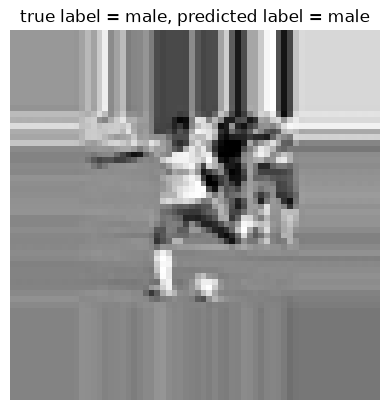

In [6]:
def int2gender(num):
    return "female" if num == 0 else "male"

random_test_index = np.random.choice(x_test.shape[0])
test_img = x_test[random_test_index]
test_label = y_test[random_test_index]
model.eval()
with torch.inference_mode():
    logits = model(torch.from_numpy(test_img).unsqueeze(0).to(device))
    pred_label = logits.argmax(dim=1).item()

plt.imshow(test_img[0], cmap="gray")
plt.title("true label = %s, predicted label = %s" % (int2gender(test_label), int2gender(pred_label)))
plt.axis("off")
plt.show()

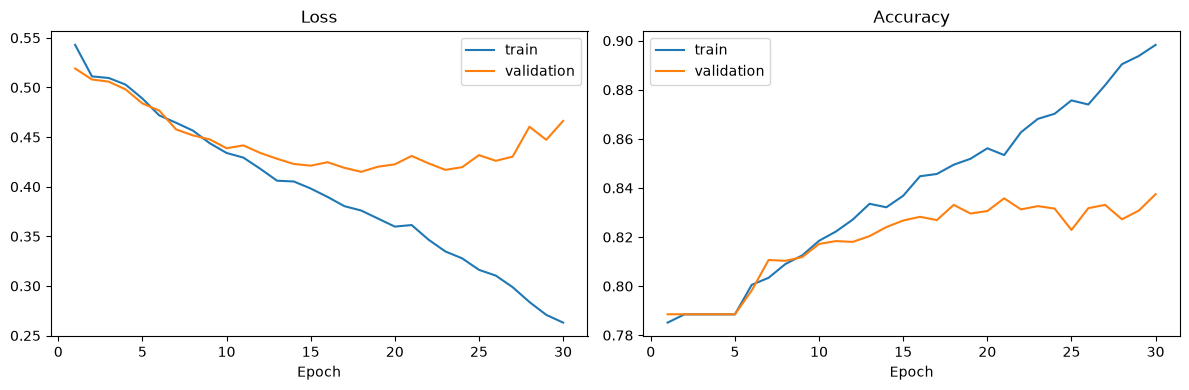

In [7]:
if RUN_TRAINING:
    epochs_range = range(1, len(history["loss"]) + 1)
    fig, axes = plt.subplots(1, 2, figsize=(12, 4))
    axes[0].plot(epochs_range, history["loss"], label="train")
    axes[0].plot(epochs_range, history["val_loss"], label="validation")
    axes[0].set_title("Loss")
    axes[0].set_xlabel("Epoch")
    axes[0].legend()
    axes[1].plot(epochs_range, history["accuracy"], label="train")
    axes[1].plot(epochs_range, history["val_accuracy"], label="validation")
    axes[1].set_title("Accuracy")
    axes[1].set_xlabel("Epoch")
    axes[1].legend()
    plt.tight_layout()
    plt.show()